# AutoValue Project
This notebook loads and explores the used car dataset.

## 1. Project Objective
The goal of this project is to analyze used -car listing data and build a model that can estimate a vehicle's market price based on characteristics such as brand, model year, mileage, fuel type, and accident history.

## 2. Dataset overview


In [2]:
## Import libraries and load dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("../data/raw/used_cars.csv")

## 3. Initial Data Inspection
Inspect the datset dimensions, column names, data types.

In [3]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [4]:
df.shape

(4009, 12)

In [5]:
df.columns

Index(['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine',
       'transmission', 'ext_col', 'int_col', 'accident', 'clean_title',
       'price'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


## 4. Data Quality Checks
Check for missing values, duplicated records, and columns with incorrect data types.

In [7]:
df.isnull().sum()

brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

## 5. Data Cleaning
Some columns require cleaning before analysis

Initial Observations:
- `milage` is stored as text.
- `price` is stored as text.
- The column `milage` is misspelled and should be renamed to `mileage`
- Miss values in some columns

### 5.1. Price and Mileage Data Type
the `price` column is currently stored as text because the values contain `$` and `,`. 
the `milage` column is stored as text because the values contain `mi.`.

In [9]:
df[["milage","price"]].dtypes

milage    object
price     object
dtype: object

In [10]:
df[["milage","price"]].head(10)

,milage,price
0,"51,000 mi.","$10,300"
1,"34,742 mi.","$38,005"
2,"22,372 mi.","$54,598"
3,"88,900 mi.","$15,500"
4,"9,835 mi.","$34,999"
5,"136,397 mi.","$14,798"
6,"84,000 mi.","$31,000"
7,"242,000 mi.","$7,300"
8,"23,436 mi.","$41,927"
9,"34,000 mi.","$69,950"


### 5.2. Create a Working Copy
A copy of the original DataFrame is created before cleaning so the raw imported data remains unchanged during experimentation.

In [11]:
df_clean = df.copy()

### 5.3. Clean `price` column

In [12]:
df_clean["price"] = df_clean["price"].str.replace("$","",regex=False).str.replace(",","",regex=False)
df_clean["price"] = pd.to_numeric(df_clean["price"])
df_clean["price"].dtype

dtype('int64')

In [13]:
df_clean["price"].head()

0    10300
1    38005
2    54598
3    15500
4    34999
Name: price, dtype: int64

### 5.4. Clean `milage` column

In [14]:
df_clean["milage"] = pd.to_numeric(
    df_clean["milage"]
    .str.replace(",","",regex=False)
    .str.replace(" mi.","",regex=False)
)
df_clean["milage"].dtype

dtype('int64')

In [15]:
# check datatype again
df_clean["milage"].head()

0    51000
1    34742
2    22372
3    88900
4     9835
Name: milage, dtype: int64

### 5.5. Rename Columns
the column `milage` is renamed to `mileage` for clearity and consitency

In [16]:
df_clean = df_clean.rename(columns={"milage":"mileage"})


In [17]:
df_clean.columns

Index(['brand', 'model', 'model_year', 'mileage', 'fuel_type', 'engine',
       'transmission', 'ext_col', 'int_col', 'accident', 'clean_title',
       'price'],
      dtype='object')

### 5.6. Missing Values
Missing values are inspected before deciding whether to remove rows, fill values, or keep them unchanged. The treatment depends on the meaning of each column and how important it is for the analysis and prediction model

In [18]:
df_clean.isnull().sum()

brand             0
model             0
model_year        0
mileage           0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

`fuel_type` has 4.24 % of mising data in the dataset
`accident` has  2.82 % of missing data in the dataset
`clean_title` has 14.87 % of missing data in the dataset

In [19]:
(df_clean.isnull().sum() / len(df_clean) * 100).round(2)

brand            0.00
model            0.00
model_year       0.00
mileage          0.00
fuel_type        4.24
engine           0.00
transmission     0.00
ext_col          0.00
int_col          0.00
accident         2.82
clean_title     14.87
price            0.00
dtype: float64

### 5.7. Inspect Categorical Columns with Missing Values
Before deciding how to handle columns having missing data, the existing categories and their frequencies are examined.

In [20]:
df_clean["fuel_type"].value_counts(dropna = False)

fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

In [21]:
df_clean["accident"].value_counts(dropna= False)

accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

In [22]:
df_clean["clean_title"].value_counts(dropna = False)

clean_title
Yes    3413
NaN     596
Name: count, dtype: int64

### 5.8. Handle Missing Categorical Values

Missing categorical values are retained rather than dropping the corresponding rows.

- Missing `fuel_type` values are labeled as `Unknown`.
- Values such as `-` and `not supported` in `fuel_type` are also treated as unavailable information.
- Missing `accident` values are labeled as `Unknown` because missing information does not necessarily mean no accident occurred.
- Missing `clean_title` values are labeled as `Unknown` because the dataset does not establish that a missing value means `No`.

This approach preserves observations while avoiding unsupported assumptions about missing information.

In [23]:
# handle NA values in fuel_type column
df_clean["fuel_type"] = (
    df_clean["fuel_type"]
        .replace(["–","not supported"],"Unknown")
        .fillna("Unknown")
)

In [24]:
df_clean["fuel_type"].value_counts(dropna=False)

fuel_type
Gasoline          3309
Unknown            217
Hybrid             194
E85 Flex Fuel      139
Diesel             116
Plug-In Hybrid      34
Name: count, dtype: int64

In [25]:
# This is show endash symbol in 
for value in df_clean["fuel_type"].unique():
    print(repr(value))

'E85 Flex Fuel'
'Gasoline'
'Hybrid'
'Unknown'
'Diesel'
'Plug-In Hybrid'


In [26]:
# clean accident
df_clean["accident"] = df_clean["accident"].fillna("Unknown")

In [27]:
df_clean["accident"].value_counts(dropna = False)

accident
None reported                             2910
At least 1 accident or damage reported     986
Unknown                                    113
Name: count, dtype: int64

In [28]:
# clean clean_title
df_clean["clean_title"] = df_clean["clean_title"].fillna("Unknown")


In [29]:
df_clean["clean_title"].value_counts(dropna=False)

clean_title
Yes        3413
Unknown     596
Name: count, dtype: int64

In [30]:
df_clean.isnull().sum()

brand           0
model           0
model_year      0
mileage         0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64

### 5.11 Validate the Cleaned Dataset
After handling data types and missing values, the cleaned dataset is checked for duplicate records, remaining missing values, and unusual numeric values.

In [31]:
df_clean.duplicated().sum()

np.int64(0)

In [32]:
df_clean[["model_year","mileage","price"]].describe()

,model_year,mileage,price
count,4009.000000,4009.000000,4.009000e+03
mean,2015.515590,64717.551010,4.455319e+04
std,6.104816,52296.599459,7.871064e+04
min,1974.000000,100.000000,2.000000e+03
25%,2012.000000,23044.000000,1.720000e+04
50%,2017.000000,52775.000000,3.100000e+04
75%,2020.000000,94100.000000,4.999000e+04
max,2024.000000,405000.000000,2.954083e+06


In [33]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   mileage       4009 non-null   int64 
 4   fuel_type     4009 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      4009 non-null   object
 10  clean_title   4009 non-null   object
 11  price         4009 non-null   int64 
dtypes: int64(3), object(9)
memory usage: 376.0+ KB


### 5.12. Inspect Potential Outliers
The numeric summary shows several extreme values, particularly in `price` and `mileage`. These observations are inspected before deciding whether they should be retained or removed. 

In [34]:
df_clean.nlargest(
    10,
    "price"
)[["brand","model","model_year","mileage","price"]]

,brand,model,model_year,mileage,price
693,Maserati,Quattroporte Base,2005,32000,2954083
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330,1950995
3046,Porsche,Carrera GT Base,2005,4400,1599000
1356,Lamborghini,Aventador SVJ Base,2021,6987,749950
624,Rolls-Royce,Cullinan,2022,398,695000
979,Lamborghini,Aventador SVJ Base,2019,6929,649999
1615,Rolls-Royce,Phantom,2023,1560,599995
1508,Rolls-Royce,Phantom,2018,7585,599000
3655,Lamborghini,Aventador S Base,2018,5858,491836
1061,Dodge,Viper GTC,2017,1389,489995


In [35]:
df_clean.nsmallest(
    10,
    "model_year"
)[["brand", "model", "model_year", "mileage", "price"]]

,brand,model,model_year,mileage,price
855,Ford,Bronco,1974,6217,115000
1088,Mazda,MX-5 Miata Base,1992,125800,11500
257,Toyota,Land Cruiser Base,1993,231500,29500
692,Honda,Civic EX,1993,58981,9599
1134,Mercedes-Benz,E-Class 400E,1993,106983,15300
1746,Nissan,300ZX Base,1993,168000,7000
1805,Mercury,Capri XR2,1993,120644,4200
2026,Mercedes-Benz,E-Class D 2.5 Turbo,1993,70015,22500
2303,Acura,NSX Base,1993,75980,90200
3469,Ford,F-250 XL SuperCab H/D,1993,115000,21900


In [36]:
df_clean.nlargest(
    10,
    "mileage"
)[["brand", "model", "model_year", "mileage", "price"]]

,brand,model,model_year,mileage,price
2764,Honda,Accord Sport,2013,405000,6000
3348,Mercedes-Benz,Sprinter 2500,2016,399000,24500
2175,Ford,Excursion Limited,2001,333361,17000
3757,Ford,F-250 XL Crew Cab Super Duty,2004,315000,9200
31,Dodge,Ram 1500 Laramie Mega Cab,2006,300183,10900
1145,GMC,Sierra 3500 SLE,2002,300000,5000
3118,Dodge,Dakota Sport,1997,285000,6399
3747,Ford,F-150 Lariat SuperCrew,2004,271000,9500
2558,Toyota,Land Cruiser Base,2010,269885,22500
3158,Toyota,4Runner 4WD,1999,267000,8000


#### Outlier Inspection Findings

The highest-priced observations are primarily luxury, exotic, or collectible vehicles, so the extreme prices are not automatically treated as data errors.

The oldest vehicles also appear to be valid used-car listings. Therefore, these observations are retained for now.

Extreme values may influence later visualizations and regression models, so their effect will be evaluated during exploratory analysis and modeling.

The highest-mileage vehicles also appear plausible given their model years and vehicle types. Therefore, no mileage observations are removed at this stage.

### 5.13. Save the Cleaned Dataset

The cleaned dataset is saved as a separate CSV file so that future analysis and modeling can use the processed data without modifying the original raw dataset.

In [37]:
df_clean.to_csv(
    "../data/cleaned/used_cars_cleaned.csv",
    index=False
)

### 5.14. Test the cleaned dataset file again

In [38]:
test_clean = pd.read_csv("../data/cleaned/used_cars_cleaned.csv")
test_clean.head()

,brand,model,model_year,mileage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Unknown,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Unknown,34999


In [39]:
test_clean.shape

(4009, 12)

## 6. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is used to understand patterns, relationships, and unusual observations in the cleaned dataset before building a machine learning model.

### 6.1. Price Distribution
The initial histogram is strongly right-skewed because a small numebr of high-priced luxury and collectible vehicles extend the price range.

In [40]:
df_clean["price"].describe()

count    4.009000e+03
mean     4.455319e+04
std      7.871064e+04
min      2.000000e+03
25%      1.720000e+04
50%      3.100000e+04
75%      4.999000e+04
max      2.954083e+06
Name: price, dtype: float64

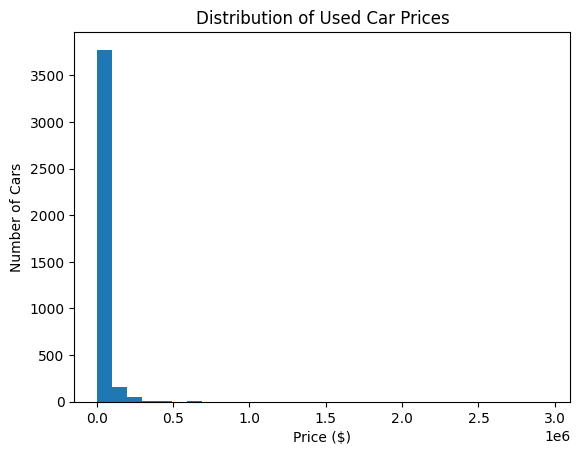

In [41]:
plt.hist(
    df_clean["price"],
    bins = 30
)
plt.xlabel("Price ($)")
plt.ylabel("Number of Cars")
plt.title("Distribution of Used Car Prices")

plt.show()

### 6.2. Remake a histogram
The 99th percentile is examined to better visualize the price range containing most observations without removing valid records from the dataset.

In [42]:
# Find price almost 99 percent cars having equal or under.
price_99 = df_clean["price"].quantile(0.99)
price_99
# set a new dataset with almost 99 percent cars having equal or lower than price_99
price_main = df_clean[df_clean["price"]<= price_99]
price_main.shape

(3968, 12)

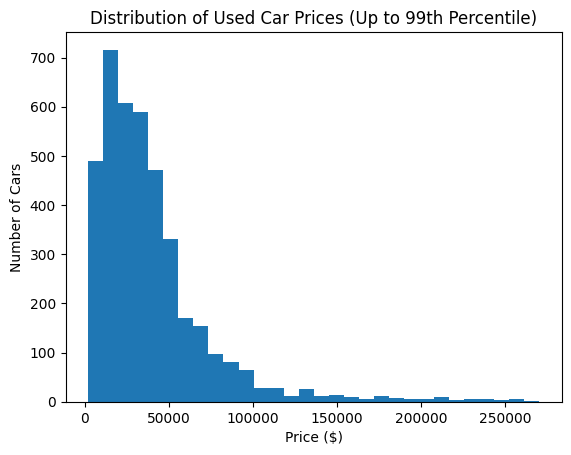

In [43]:
plt.hist(
    price_main["price"],
    bins = 30
)
plt.xlabel("Price ($)")
plt.ylabel("Number of Cars")
plt.title("Distribution of Used Car Prices (Up to 99th Percentile)")

plt.show()

#### Finding

Used-car prices are strongly right-skewed. Most vehicles are concentrated in the lower price range, while a relatively small number of expensive vehicles create a long right tail.

The visualization is limited to the 99th percentile of price to make the main distribution easier to interpret. The high-priced observations are retained in the original cleaned dataset.

### 6.3. Relationship between Mileage and Price

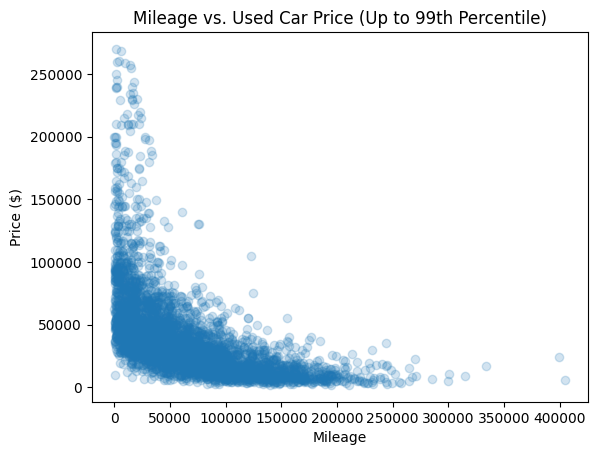

In [44]:
plt.scatter(
    price_main["mileage"],
    price_main["price"],
    alpha = 0.2
)

plt.xlabel("Mileage")
plt.ylabel("Price ($)")
plt.title("Mileage vs. Used Car Price (Up to 99th Percentile)")

plt.show()

### Finding
Used-car price generally decrease as mileage increase, so it shows a negative association between mileage and price. However, there is substabtial variation among lower-mileage vehicles, indicating that other vehicle characteristics also influence price.

### 6.4. Relationship between model year and price

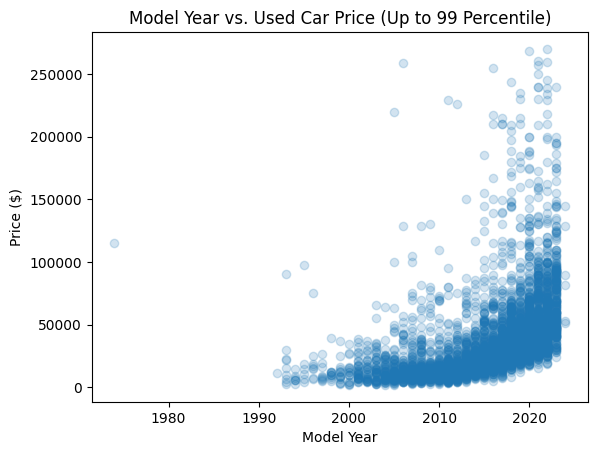

In [45]:
plt.scatter(
    price_main["model_year"],
    price_main["price"],
    alpha = 0.2
)
plt.xlabel("Model Year")
plt.ylabel("Price ($)")
plt.title("Model Year vs. Used Car Price (Up to 99 Percentile)")

plt.show()

### Finding
Newer vehicles tend to have higher prices, suggesting a positive association between model year and price.

### 6.5. Average Price by Brand


In [46]:
avg_price_by_brand = df_clean.groupby("brand")["price"].mean()
avg_price_by_brand

brand
Acura            2.803408e+04
Alfa             3.768605e+04
Aston            1.151996e+05
Audi             3.990743e+04
BMW              4.107231e+04
Bentley          1.375535e+05
Bugatti          1.950995e+06
Buick            2.035767e+04
Cadillac         4.167073e+04
Chevrolet        3.672274e+04
Chrysler         1.381279e+04
Dodge            3.450054e+04
FIAT             1.479960e+04
Ferrari          2.437907e+05
Ford             3.624088e+04
GMC              3.752568e+04
Genesis          4.327990e+04
Honda            2.195903e+04
Hummer           1.961806e+04
Hyundai          1.894688e+04
INFINITI         2.292764e+04
Jaguar           3.236272e+04
Jeep             3.109979e+04
Karma            5.325000e+04
Kia              2.809642e+04
Lamborghini      2.912338e+05
Land             5.576406e+04
Lexus            3.566852e+04
Lincoln          2.833088e+04
Lotus            5.481250e+04
Lucid            1.019663e+05
MINI             1.415764e+04
Maserati         1.405825e+05
Mayb

In [47]:
avg_price_by_brand = avg_price_by_brand.sort_values(ascending=False)
avg_price_by_brand.head(10)

brand
Bugatti        1.950995e+06
Rolls-Royce    3.709927e+05
Lamborghini    2.912338e+05
Ferrari        2.437907e+05
McLaren        2.134575e+05
Maserati       1.405825e+05
Bentley        1.375535e+05
Aston          1.151996e+05
Lucid          1.019663e+05
Rivian         9.313818e+04
Name: price, dtype: float64

In [48]:
brand_counts = df_clean["brand"].value_counts()
brand_counts.head(20)

brand
Ford             386
BMW              375
Mercedes-Benz    315
Chevrolet        292
Porsche          201
Audi             200
Toyota           199
Lexus            163
Jeep             143
Land             130
Nissan           116
Cadillac         107
GMC               91
RAM               91
Dodge             90
Tesla             87
Kia               76
Hyundai           72
Subaru            64
Acura             64
Name: count, dtype: int64

In [49]:
brand_counts["Bugatti"]

np.int64(1)

In [50]:
brand_counts["Toyota"]

np.int64(199)

### Brand-Level  Summary
Average price alone can be misleading when a brand has very few listings. Therefore, average is combined with the number of listings for each brand before making comparisons.

In [51]:
brand_summary = pd.DataFrame({
    "avg_price": avg_price_by_brand,
    "n_listings": brand_counts
})

brand_summary.head()

,avg_price,n_listings
brand,,
Acura,28034.078125,64
Alfa,37686.052632,19
Aston,115199.555556,9
Audi,39907.430000,200
BMW,41072.309333,375


In [52]:
brand_summary_filtered = brand_summary[
    brand_summary["n_listings"] >= 20
]

In [53]:
brand_summary_filtered = brand_summary_filtered.sort_values(
    "avg_price",
    ascending = False
)

brand_summary_filtered.head(10)

,avg_price,n_listings
brand,,
Lamborghini,291233.846154,26
Maserati,140582.529412,34
Bentley,137553.545455,33
Porsche,88751.298507,201
Land,55764.061538,130
Mercedes-Benz,52075.765079,315
Tesla,48439.471264,87
Genesis,43279.900000,20
RAM,43029.164835,91


### Average Price by Brand

In [54]:
top10_brands = brand_summary_filtered.head(10)

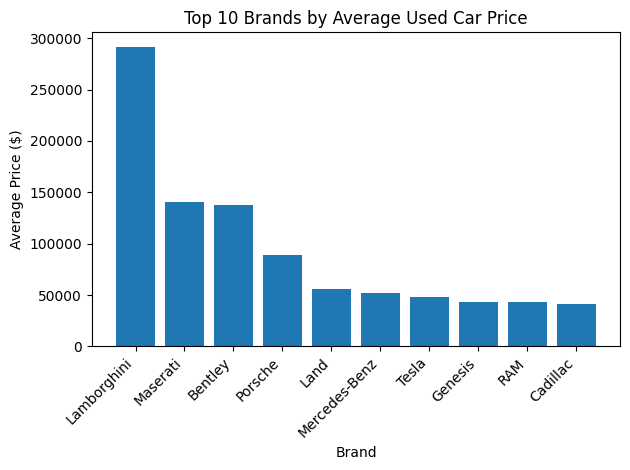

In [55]:
plt.bar(
    top10_brands.index,
    top10_brands["avg_price"]
)

plt.xlabel("Brand")
plt.ylabel("Average Price ($)")
plt.title("Top 10 Brands by Average Used Car Price")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### Finding
Among brands with at least 20 listings, Lamborghini has the highest average listed price, followed by Maserati and Bentley. Requiring a minimum number of listings reduces the influence of brands represented by only a few vehicles.
Average price may still be affected by unusually expensive vehicles, so sample size and price distribution should be considered when interpreting these comparisons.

### 6.6. Accident History and Vehicle Price

In [56]:
accident_summary = (
    df_clean.groupby("accident")["price"]
    .agg(["mean","median","count"])
)
accident_summary

,mean,median,count
accident,,,
At least 1 accident or damage reported,28831.500000,20900.0,986
None reported,49638.073196,35667.5,2910
Unknown,50788.389381,36500.0,113


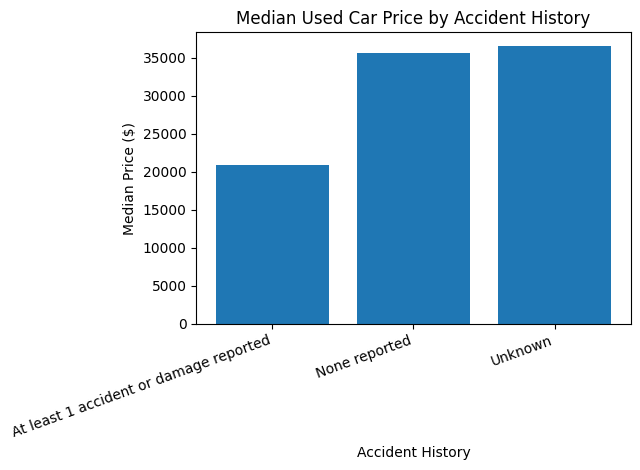

In [57]:
plt.bar(
    accident_summary.index,
    accident_summary["median"]
)
plt.xlabel("Accident History")
plt.ylabel("Median Price ($)")
plt.title("Median Used Car Price by Accident History")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

#### Finding

Vehicles with at least one reported accident or damage have substantially lower typical prices than vehicles with no reported accidents.

Because vehicle prices are strongly right-skewed, the median is used as a more robust measure of typical price than the mean. The `Unknown` category contains relatively few observations, so it should be interpreted cautiously.

### 6.7. Clean Title and Vehicle Price

In [58]:
clean_title_summary = (
    df_clean.groupby("clean_title")["price"]
    .agg(["mean","median","count"])
)

clean_title_summary

,mean,median,count
clean_title,,,
Unknown,60695.077181,42996.5,596
Yes,41734.390272,29000.0,3413


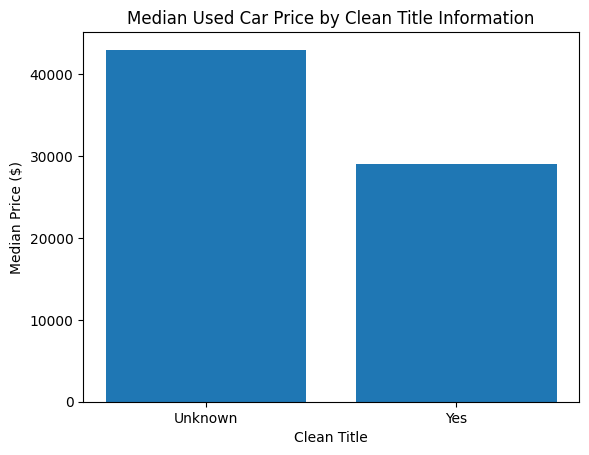

In [59]:
plt.bar(
    clean_title_summary.index,
    clean_title_summary["median"]
)

plt.xlabel("Clean Title")
plt.ylabel("Median Price ($)")
plt.title("Median Used Car Price by Clean Title Information")

plt.show()

#### Finding
Vehicle with unknown clean-title information have a higher median listed price than vehicle explicitly marked as haivng a clean title.
However, `Unknown` represents missing title information rather than a confirmed negative title status. 

### 6.8. Fuel Type and Vehicle Price

In [60]:
fuel_summary = (
    df_clean.groupby("fuel_type")["price"]
    .agg(["mean","median","count"])
)
fuel_summary

,mean,median,count
fuel_type,,,
Diesel,48695.422414,45450.0,116
E85 Flex Fuel,22744.115108,19500.0,139
Gasoline,44538.525839,29950.0,3309
Hybrid,51426.195876,45499.0,194
Plug-In Hybrid,45946.176471,44945.0,34
Unknown,50169.608295,43000.0,217


#### Finding
Median vehicle prices vary across fuel types. Hybrid and diesel vehicles have relatively high median listed prices, while E85 have the lowest median value.


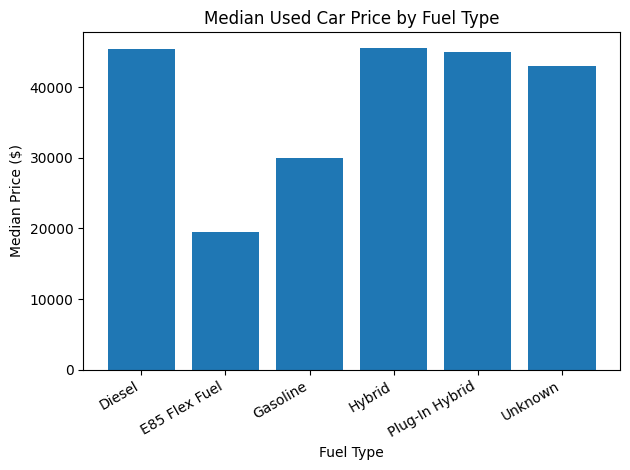

In [61]:
plt.bar(
    fuel_summary.index,
    fuel_summary["median"]
)

plt.xlabel("Fuel Type")
plt.ylabel("Median Price ($)")
plt.title("Median Used Car Price by Fuel Type")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 6.9. Transmission Categories

In [62]:
df_clean["transmission"].nunique()

62

In [63]:
df_clean["transmission"].value_counts().head(20)

transmission
A/T                               1037
8-Speed A/T                        406
Transmission w/Dual Shift Mode     398
6-Speed A/T                        362
6-Speed M/T                        248
Automatic                          237
7-Speed A/T                        209
8-Speed Automatic                  176
10-Speed A/T                       119
5-Speed A/T                         86
9-Speed A/T                         74
6-Speed Automatic                   73
4-Speed A/T                         72
1-Speed A/T                         64
CVT Transmission                    62
5-Speed M/T                         59
10-Speed Automatic                  56
9-Speed Automatic                   47
M/T                                 40
Automatic CVT                       37
Name: count, dtype: int64

#### Transmission Standardization

The dataset contains 62 different transmission descriptions, including multiple labels that represent similar transmission types. Rather than comparing all raw labels directly, common text patterns are inspected before creating broader transmission categories.

#### Identify Transmission Patterns

Boolean masks are created for common transmission patterns. Because some descriptions may match more than one pattern, overlaps are inspected before assigning simplified categories.

In [64]:
is_cvt = df_clean["transmission"].str.contains(
    "CVT",
    case=False,
    na=False
)

is_manual = df_clean["transmission"].str.contains(
    "M/T",
    case=False,
    na=False,
    regex=False
)

is_automatic = (
    df_clean["transmission"].str.contains(
        "A/T",
        case=False,
        na=False,
        regex=False
    )
    |
    df_clean["transmission"].str.contains(
        "Automatic",
        case=False,
        na=False
    )
)

is_dual_shift = df_clean["transmission"].str.contains(
    "Dual Shift",
    case=False,
    na=False
)

In [65]:
(is_cvt & is_automatic).sum()

np.int64(37)

In [66]:
matched = (
    is_cvt
    | is_manual
    | is_automatic
    | is_dual_shift
)

In [67]:
# find transmission not covered by any rule
df_clean.loc[
    ~matched,
    "transmission"
].value_counts()

transmission
6-Speed Manual                    8
Transmission Overdrive Switch     7
–                                 4
Variable                          4
2                                 3
F                                 2
7-Speed Manual                    2
Manual                            2
Manual, 6-Spd                     2
8-SPEED AT                        1
Auto, 6-Spd w/CmdShft             1
6-Speed                           1
Single-Speed Fixed Gear           1
7-Speed                           1
6 Speed At/Mt                     1
SCHEDULED FOR OR IN PRODUCTION    1
6 Speed Mt                        1
8-Speed Manual                    1
Name: count, dtype: int64

In [68]:
# adjust the manual masks again
is_manual = (
    df_clean["transmission"].str.contains(
        "M/T",
        case = False,
        na = False,
        regex= False
    )
    |
    df_clean["transmission"].str.contains(
        "Manual",
        case = False,
        na = False,
    )
)

is_manual.sum()

np.int64(374)

In [69]:
# adjust the automatic masks again
is_automatic = (
    df_clean["transmission"].str.contains(
        "A/T",
        case=False,
        na=False,
        regex=False
    )
    |
    df_clean["transmission"].str.contains(
        "Automatic",
        case=False,
        na=False
    )
    |
    df_clean["transmission"].str.contains(
        "Auto",
        case=False,
        na=False
    )
)

is_automatic.sum()

np.int64(3149)

In [70]:
matched = (
    is_cvt
    | is_manual
    | is_automatic
    | is_dual_shift
)

df_clean.loc[
    ~matched,
    "transmission"
].value_counts()

transmission
Transmission Overdrive Switch     7
Variable                          4
–                                 4
2                                 3
F                                 2
8-SPEED AT                        1
6-Speed                           1
Single-Speed Fixed Gear           1
7-Speed                           1
6 Speed At/Mt                     1
SCHEDULED FOR OR IN PRODUCTION    1
6 Speed Mt                        1
Name: count, dtype: int64

#### Create Simplified Transmission Groups
The orignial transmission column contains many inconsistent descriptions. A new `transmission_group` feature is created using broader categories while preserving the original transmission information.

In [71]:
df_clean["transmission_group"] = np.select(
    [
        is_cvt,
        is_dual_shift,
        is_manual,
        is_automatic
    ],
    [
        "CVT",
        "Dual Shift",
        "Manual",
        "Automatic"
    ],
    default="Other"
)

In [72]:
df_clean["transmission_group"].value_counts()

transmission_group
Automatic     3110
Dual Shift     398
Manual         374
CVT            100
Other           27
Name: count, dtype: int64

In [73]:
df_clean[
    ["transmission","transmission_group"]
].sample(15)

,transmission,transmission_group
3868,4-Speed A/T,Automatic
999,6-Speed A/T,Automatic
694,Transmission w/Dual Shift Mode,Dual Shift
3563,Transmission w/Dual Shift Mode,Dual Shift
1246,6-Speed M/T,Manual
2193,A/T,Automatic
3359,A/T,Automatic
2409,CVT Transmission,CVT
1826,A/T,Automatic
3604,6-Speed Automatic,Automatic


Most records were successfully classified as Automatic, Dual Shift, Manual, or CVT. A small number of ambiguous transmission descriptions were assigned to `Other`.

#### 6.9.1. Median price by transmission group

In [74]:
transmission_summary = (
    df_clean.groupby("transmission_group")["price"]
    .agg(["mean","median","count"])
)

transmission_summary

,mean,median,count
transmission_group,,,
Automatic,43894.585852,32000.0,3110
CVT,23528.840000,23947.5,100
Dual Shift,54710.615578,34000.0,398
Manual,41442.965241,23875.0,374
Other,91637.037037,41598.0,27


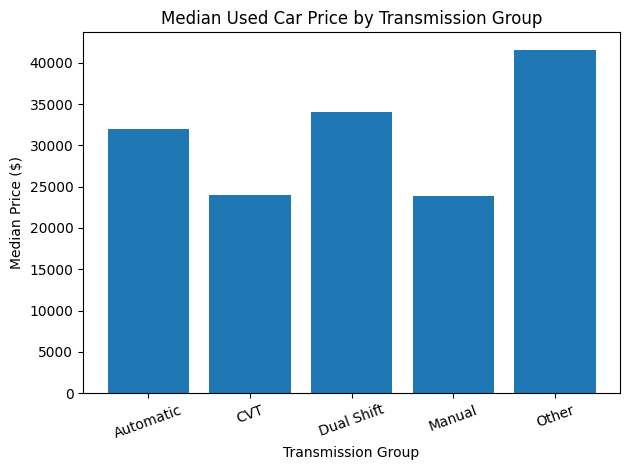

In [75]:
plt.bar(
    transmission_summary.index,
    transmission_summary["median"]
)

plt.xlabel("Transmission Group")
plt.ylabel("Median Price ($)")
plt.title("Median Used Car Price by Transmission Group")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#### Finding

Median listed prices vary across transmission groups. Among the major transmission categories, Dual Shift vehicles have the highest median price, followed by Automatic vehicles.

CVT and Manual vehicles have lower median prices in this dataset. The `Other` category has a relatively high median price but contains only 27 observations, so it should be interpreted cautiously.

The differences between mean and median prices in several groups also indicate that high-price outliers influence the mean.

## 7. Key Findings

- Used-car prices are strongly right-skewed. Most vehicles are concentrated in lower price ranges, while a small number of luxury and collectible vehicles create a logn right tail.
- Milleage has a negative association with listed price. Higher-mileage vehicles generally have lower prices.
- Model year has a positive association with price. Newer vehicles.
- Among brands with at least 20 listings, Lamborghini, Maserati, and Bentley have some of the highest average prices.
- Vehicles with reported accidents or damage have a substantially lower median price than vehicles with no reported accidents.
- Median prices differ across fuel types, with Hybrid and Diesel vehicles showing relatively high median prices in this dataset.
- Transmission descriptions required feature engineering because the raw data contained 62 different labels. These were simplified into Automatic, Dual Shift, Manual, CVT, and Other categories.

## 8. Conclusion and Next Steps

The exploratory analysis identified several variables that appear useful for predicting vehicle price, including mileage, model year, brand, accident history, fuel type, and transmission type.

The next stage of the project will use the cleaned data for SQL analysis and machine learning. A regression model will be developed to estimate used-car prices based on vehicle characteristics.

In [76]:
## Save the cleaned_used_car.csv again because we add new feature "transmission group"
df_clean.to_csv(
    "../data/cleaned/used_cars_cleaned.csv",
    index = False
)